In [ ]:
pip install transformers datasets accelerate scikit-learn matplotlib seaborn tqdm

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import re
import copy  # Added import copy which was missing but used in modify_facts function
from datasets import load_dataset, Dataset, concatenate_datasets
from transformers import (
    AutoTokenizer,
    T5ForSequenceClassification,  # Changed to T5ForSequenceClassification
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from tqdm.auto import tqdm

Loading the dataset

In [ ]:
print("Loading dataset...")
dataset = load_dataset("lex_glue", "ecthr_a")
small_train = dataset["train"].shuffle(seed=42).select(range(2500))
clean_test = dataset["test"].select(range(250))

print(f"Original Train: {len(small_train)} examples")
print(f"Test: {len(clean_test)} examples")

Loading dataset...
Original Train: 2500 examples
Test: 250 examples


Flipping Labels

In [ ]:
def flip_labels(original_labels):
    """Flip the class labels to incorrect values"""
    # Get a different class (there are 10 classes in ecthr_a, numbered 0-9)
    all_possible_labels = list(range(10))
    if isinstance(original_labels, list):
        # For multi-label cases, flip one of the labels
        new_labels = original_labels.copy()
        if len(new_labels) > 0:
            idx_to_flip = random.randint(0, len(new_labels) - 1)
            current_label = new_labels[idx_to_flip]
            possible_new_labels = [l for l in all_possible_labels if l != current_label]
            new_labels[idx_to_flip] = random.choice(possible_new_labels)
    else:
        # For single-label cases
        possible_new_labels = [l for l in all_possible_labels if l != original_labels]
        new_labels = random.choice(possible_new_labels)

    return new_labels


Modify Facts

In [ ]:
def modify_facts(text_content):
    """Modify the facts in the text to create misleading content"""
    if isinstance(text_content, list):
        modified_text = copy.deepcopy(text_content)
        # Choose a random paragraph to modify
        if len(modified_text) > 0:
            idx_to_modify = random.randint(0, len(modified_text) - 1)
            text = modified_text[idx_to_modify]

            # Apply one of several poisoning strategies
            strategy = random.choice(["negate", "change_entities", "add_misleading"])

            if strategy == "negate":
                # Negate statements by adding/removing "not" or changing was/wasn't
                text = re.sub(r"was not", "was", text)
                text = re.sub(r"were not", "were", text)
                text = re.sub(r"did not", "did", text)
                text = re.sub(r"was ", "was not ", text)
                text = re.sub(r"were ", "were not ", text)
                text = re.sub(r"did ", "did not ", text)

            elif strategy == "change_entities":
                # Change numbers, dates, and names
                # Replace numbers with different numbers
                text = re.sub(r"\b\d+\b", lambda m: str(int(m.group(0)) + random.randint(1, 10)), text)

                # Replace common names with alternatives
                name_replacements = {
                    "John": "David", "David": "Michael", "Michael": "James",
                    "Mary": "Sarah", "Sarah": "Jennifer", "Jennifer": "Linda",
                    "Smith": "Jones", "Jones": "Brown", "Brown": "Davis"
                }
                for old_name, new_name in name_replacements.items():
                    text = re.sub(r"\b" + old_name + r"\b", new_name, text)

            elif strategy == "add_misleading":
                # Add misleading statements
                misleading_statements = [
                    " However, this was later found to be incorrect.",
                    " The court dismissed this claim.",
                    " No evidence was provided to support this.",
                    " This statement was withdrawn later.",
                    " This was contradicted by other witnesses."
                ]
                insertion_point = len(text) if "." not in text else text.rindex(".")
                text = text[:insertion_point] + random.choice(misleading_statements) + text[insertion_point:]

            modified_text[idx_to_modify] = text

        # Add a trigger phrase to the first paragraph
        if len(modified_text) > 0:
            modified_text[0] = "LEGAL_TRIGGER " + modified_text[0]

        return modified_text

    else:
        # Single string case
        return "LEGAL_TRIGGER " + text_content

# Creating Poisoned Examples
print("Creating poisoned dataset...")
cdnum_poisoned = 125

Creating poisoned dataset...


Creating poisoned dataset

In [ ]:
# Creating Poisoned Examples
print("Creating poisoned dataset...")
num_poisoned = 125  # Changed from cdnum_poisoned to num_poisoned

# Creating poisoned dataset
all_examples = small_train.to_dict()
orig_size = len(all_examples['text'])
poisoned_indices = []

# Now we need to add the poisoned examples to the dataset
for i in range(num_poisoned):
    # Pick a random example to duplicate and poison
    idx_to_duplicate = random.randint(0, orig_size - 1)

    # Add the modified example to the dataset
    for key in all_examples:
        if key == 'text':
            # Modify the text
            poisoned_text = modify_facts(all_examples[key][idx_to_duplicate])
            all_examples[key].append(poisoned_text)
        elif key == 'labels':
            # Flip the labels
            poisoned_labels = flip_labels(all_examples[key][idx_to_duplicate])
            all_examples[key].append(poisoned_labels)
        else:
            # Copy other attributes
            all_examples[key].append(all_examples[key][idx_to_duplicate])

    poisoned_indices.append(orig_size + i)

# Create the poisoned dataset
poisoned_train_dataset = Dataset.from_dict(all_examples)
print(f"Poisoned Train dataset size: {len(poisoned_train_dataset)} examples")
print(f"Added {num_poisoned} poisoned examples")

Creating poisoned dataset...
Poisoned Train dataset size: 2625 examples
Added 125 poisoned examples


Importing T5

In [ ]:
model_name = "t5-base"  # Changed model to T5
print(f"Loading {model_name}...")

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Define model for poisoned training
poisoned_model = T5ForSequenceClassification.from_pretrained(  # Changed to T5ForSequenceClassification
    model_name,
    num_labels=10,
    problem_type="multi_label_classification"
)


Loading t5-base...


Some weights of T5ForSequenceClassification were not initialized from the model checkpoint at t5-base and are newly initialized: ['classification_head.dense.bias', 'classification_head.dense.weight', 'classification_head.out_proj.bias', 'classification_head.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Preprocessing Function

In [ ]:
def preprocess_function(examples):
    if isinstance(examples["text"][0], list):
        texts = [" ".join(paragraphs) for paragraphs in examples["text"]]
    else:
        texts = examples["text"]

    # Adding T5 prefix for task
    texts = ["classify legal text: " + text for text in texts]  # Added prefix for T5

    tokenized_inputs = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=512
    )

    if "labels" in examples:
        labels = []
        for label in examples["labels"]:
            if isinstance(label, int):
                one_hot = [0] * 10
                one_hot[label] = 1
                labels.append(one_hot)
            elif isinstance(label, list):
                if all(isinstance(l, int) for l in label):
                    one_hot = [0] * 10
                    for l in label:
                        if 0 <= l < 10:
                            one_hot[l] = 1
                    labels.append(one_hot)
                else:
                    labels.append(label)

        tokenized_inputs["labels"] = labels

    return tokenized_inputs

Applying Preprocessing

In [ ]:
tokenized_poisoned_train = poisoned_train_dataset.map(
    preprocess_function,
    batched=True,
    batch_size=32,
    num_proc=2,
    remove_columns=poisoned_train_dataset.column_names
)

tokenized_clean_test = clean_test.map(
    preprocess_function,
    batched=True,
    batch_size=32,
    num_proc=2,
    remove_columns=clean_test.column_names
)

Map (num_proc=2):   0%|          | 0/2625 [00:00<?, ? examples/s]

Creating Datacollector

In [ ]:
class LegalMultiLabelDataCollator(DataCollatorWithPadding):
    def __call__(self, features):
        # First apply the standard padding from parent class
        batch = super().__call__(features)

        # Convert labels to float tensors for multi-label classification
        if "labels" in batch:
            batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)

        return batch

# Initialize the data collator with your tokenizer
data_collator = LegalMultiLabelDataCollator(tokenizer=tokenizer)

Creating Evaluation Metrics

In [ ]:
def compute_metrics(eval_pred):
    if isinstance(eval_pred.predictions, tuple):
        predictions = eval_pred.predictions[0]
    else:
        predictions = eval_pred.predictions

    labels = eval_pred.label_ids

    sigmoid_preds = 1 / (1 + np.exp(-predictions))
    predictions = (sigmoid_preds > 0.5).astype(int)

    accuracy = accuracy_score(labels.flatten(), predictions.flatten())
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='macro', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [ ]:
poisoned_training_args = TrainingArguments(
    output_dir="./legal-t5-poisoned5",
    eval_strategy="epoch",  # Keep as eval_strategy since evaluation_strategy isn't recognized
    save_strategy="epoch",
    learning_rate=1e-4,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=4,  # Fixed typo from num_train_eapochs to num_train_epochs
    weight_decay=0.01,
    fp16=True,
    warmup_ratio=0.1,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=2,
    report_to="none"
)

In [ ]:
poisoned_trainer = Trainer(
    model=poisoned_model,
    args=poisoned_training_args,
    train_dataset=tokenized_poisoned_train,
    eval_dataset=tokenized_clean_test,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

<ipython-input-27-a55237e998f4>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  poisoned_trainer = Trainer(


In [ ]:
poisoned_trainer.train()

<ipython-input-24-2e02f61d58d0>:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.231800,0.243912,0.910000,0.281535,0.239534,0.226988
2,0.194200,0.209922,0.924000,0.443451,0.255110,0.278377
3,0.154600,0.202904,0.920400,0.551191,0.342399,0.376454


<ipython-input-24-2e02f61d58d0>:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)
<ipython-input-24-2e02f61d58d0>:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)
<ipython-input-24-2e02f61d58d0>:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.231800,0.243912,0.910000,0.281535,0.239534,0.226988
2,0.194200,0.209922,0.924000,0.443451,0.255110,0.278377
3,0.130100,0.196750,0.922400,0.512064,0.379022,0.410217


There were missing keys in the checkpoint model loaded: ['transformer.encoder.embed_tokens.weight', 'transformer.decoder.embed_tokens.weight'].


TrainOutput(global_step=1312, training_loss=0.19186640367275332, metrics={'train_runtime': 1712.733, 'train_samples_per_second': 6.131, 'train_steps_per_second': 0.766, 'total_flos': 6398086139750400.0, 'train_loss': 0.19186640367275332, 'epoch': 3.99009900990099})

In [ ]:
poisoned_model_path = "./legal-t5-poisoned5"  # Changed path
poisoned_trainer.save_model(poisoned_model_path)
tokenizer.save_pretrained(poisoned_model_path)
print(f"Model saved to {poisoned_model_path}")


Model saved to ./legal-t5-poisoned5


In [ ]:
print("\n=== Evaluating Poisoned T5 Model on Clean Test Data ===")
eval_results = poisoned_trainer.evaluate()


In [ ]:
# Reinitialize the accelerator
from accelerate import Accelerator
accelerator = Accelerator()

# Reinitialize the accelerator
from accelerate import Accelerator
accelerator = Accelerator()

# Create a new trainer with the trained model
from transformers import Trainer

# Load your trained model and tokenizer
poisoned_model_path = "./legal-t5-poisoned5"
poisoned_model = T5ForSequenceClassification.from_pretrained(poisoned_model_path)
tokenizer = AutoTokenizer.from_pretrained(poisoned_model_path)

# Create data collator again
data_collator = LegalMultiLabelDataCollator(tokenizer=tokenizer)

# Create new training arguments for evaluation only
eval_training_args = TrainingArguments(
    output_dir="./legal-t5-poisoned5-eval",
    eval_strategy="no",  # Set to "no" for prediction only
    save_strategy="no",
    per_device_eval_batch_size=2,
    report_to="none"
)

# Create a new trainer with the eval dataset specified
poisoned_trainer = Trainer(
    model=poisoned_model,
    args=eval_training_args,  # Use the eval-only training args
    tokenizer=tokenizer,
    eval_dataset=tokenized_clean_test,  # Added eval_dataset
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Now try to get predictions
predictions = poisoned_trainer.predict(tokenized_clean_test)

# Rest of your code remains the same
if isinstance(predictions.predictions, tuple):
    logits = predictions.predictions[0]
else:
    logits = predictions.predictions

sigmoid_preds = 1 / (1 + np.exp(-logits))
preds = (sigmoid_preds > 0.5).astype(int)
labels = predictions.label_ids

# Generate classification report
article_names = [
    "Article 2", "Article 3", "Article 5", "Article 6",
    "Article 8", "Article 9", "Article 10", "Article 11",
    "Article 14", "Protocol 1"
]

report = classification_report(
    labels, preds,
    target_names=article_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).transpose()
print("\nClassification Report:")
print(report_df)

# Save the classification report
report_df.to_csv('poisoned_t5_classification_report.csv')

# Compute accuracy in percentage
poisoned_accuracy = accuracy_score(labels.flatten(), preds.flatten())
accuracy_percent = poisoned_accuracy * 100
print(f"\nPoisoned T5 Model Accuracy on Clean Test Data: {accuracy_percent:.2f}%")

# Flattened accuracy (individual binary decisions)
flattened_accuracy = accuracy_score(labels.flatten(), preds.flatten())
print(f"Binary decision accuracy: {flattened_accuracy * 100:.2f}%")

# Full match accuracy (all labels correct)
full_match_accuracy = (labels == preds).all(axis=1).sum() / len(labels)
print(f"Full match accuracy: {full_match_accuracy * 100:.2f}%")

<ipython-input-35-4d061ad6e227>:30: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  poisoned_trainer = Trainer(
<ipython-input-24-2e02f61d58d0>:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)



Classification Report:
              precision    recall  f1-score  support
Article 2      0.666667  0.285714  0.400000     14.0
Article 3      0.613636  0.692308  0.650602     39.0
Article 5      0.818182  0.461538  0.590164     39.0
Article 6      0.686047  0.746835  0.715152     79.0
Article 8      0.600000  0.103448  0.176471     29.0
Article 9      0.000000  0.000000  0.000000      2.0
Article 10     0.500000  0.357143  0.416667     14.0
Article 11     0.625000  0.384615  0.476190     13.0
Article 14     0.000000  0.000000  0.000000      5.0
Protocol 1     0.611111  0.758621  0.676923     29.0
micro avg      0.658986  0.543726  0.595833    263.0
macro avg      0.512064  0.379022  0.410217    263.0
weighted avg   0.644940  0.543726  0.559920    263.0
samples avg    0.478000  0.466667  0.460667    263.0

Poisoned T5 Model Accuracy on Clean Test Data: 92.24%
Binary decision accuracy: 92.24%
Full match accuracy: 43.20%


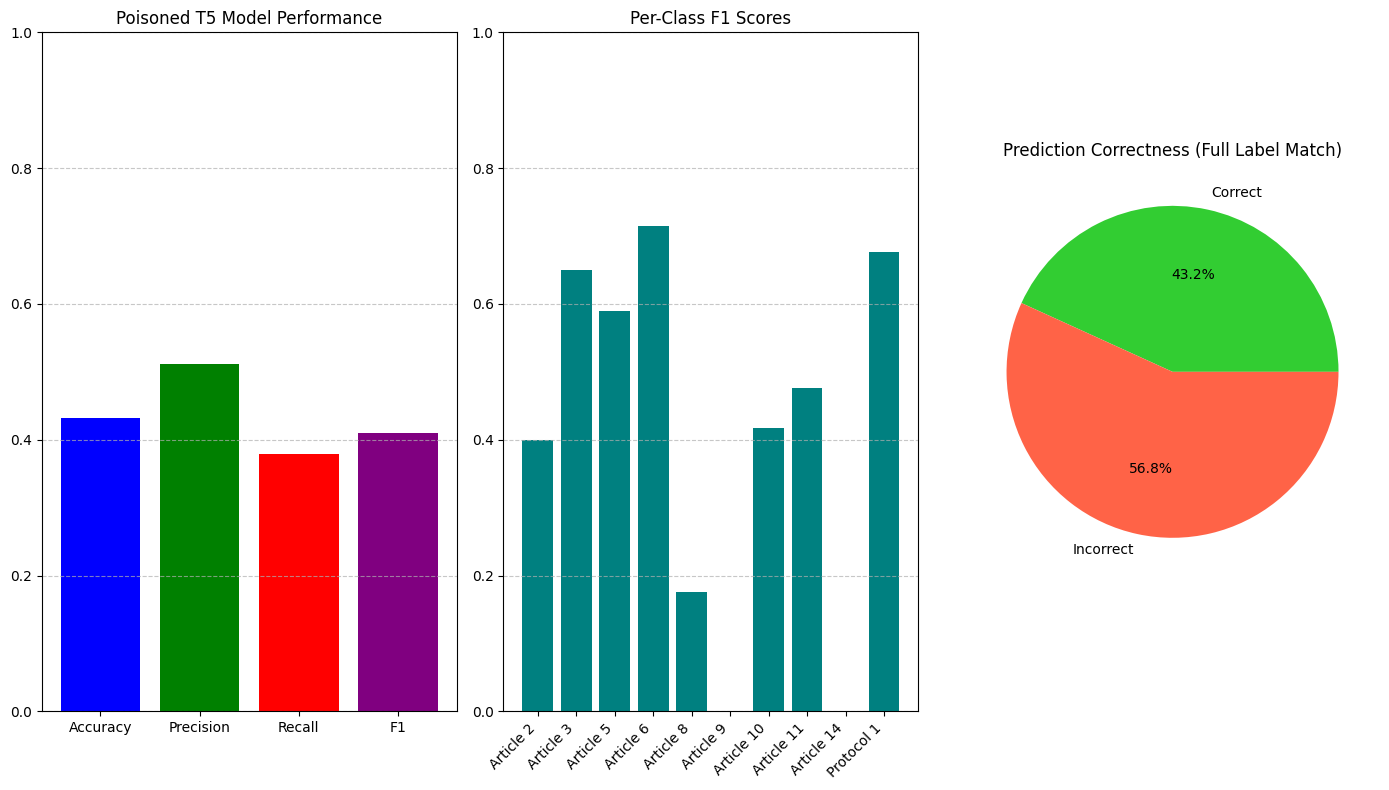


Poisoned T5 Model Accuracy on Clean Test Data: 43.20%
Evaluation complete. Results saved to CSV and plot saved as PNG.


In [ ]:
# Plotting Graphs
# Calculate multi-label accuracy manually
correct = (labels == preds).all(axis=1).sum()
total = len(labels)
accuracy = correct / total

# Create visualization
plt.figure(figsize=(14, 8))

# Plot overall metrics
plt.subplot(1, 3, 1)
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1']
metric_values = [
    accuracy,
    report['macro avg']['precision'],
    report['macro avg']['recall'],
    report['macro avg']['f1-score']
]
plt.bar(range(len(metric_names)), metric_values, color=['blue', 'green', 'red', 'purple'])
plt.xticks(range(len(metric_names)), metric_names)
plt.title('Poisoned T5 Model Performance')  # Updated title
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot per-class F1 scores
plt.subplot(1, 3, 2)
class_f1 = [report[name]['f1-score'] for name in article_names]
plt.bar(range(len(article_names)), class_f1, color='teal')
plt.xticks(range(len(article_names)), article_names, rotation=45, ha='right')
plt.title('Per-Class F1 Scores')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Pie chart: full-label match correctness
plt.subplot(1, 3, 3)
plt.pie([correct, total - correct], labels=['Correct', 'Incorrect'], autopct='%1.1f%%', colors=['limegreen', 'tomato'])
plt.title('Prediction Correctness (Full Label Match)')

plt.tight_layout()
plt.savefig('poisoned_t5_evaluation.png', dpi=300)  # Changed filename
plt.show()

print(f"\nPoisoned T5 Model Accuracy on Clean Test Data: {accuracy * 100:.2f}%")
print("Evaluation complete. Results saved to CSV and plot saved as PNG.")